# 🏨 Hotel Booking & Cancellation Analysis

## Project Overview

This project analyzes hotel booking data to identify factors associated with booking cancellations and to generate actionable business insights for improving cancellation management.

The analysis combines **data cleaning, exploratory data analysis, statistical hypothesis testing, effect-size analysis, and interactive visualization** using Python.

### Business Question

> **What factors are associated with hotel booking cancellations, and what actionable insights can hotels use to improve booking management and reduce cancellation risk?**

### Tools Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Plotly
- SciPy
- Google Colab


## 1. Import Libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Make visualizations look cleaner
sns.set_theme(style="whitegrid")

## 2. Load Dataset


In [2]:
df = pd.read_csv("/content/hotel_bookings.csv")

FileNotFoundError: [Errno 2] No such file or directory: '/content/hotel_bookings.csv'

## 3. Data Understanding


In [ ]:
df.head(10)

In [ ]:
df.tail(10)

In [ ]:
df.shape

Each row represents a hotel booking. The dataset contains information such as hotel type, cancellation status, lead time, arrival information, customer details, booking channel, deposit type and ADR

In [ ]:
df.columns.tolist()

## 4. Data Cleaning


In [3]:
print("Duplicates:", df.duplicated().sum())

NameError: name 'df' is not defined

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
print(df['hotel'].value_counts())

hotel
City Hotel      53428
Resort Hotel    33968
Name: count, dtype: int64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 87396 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           87396 non-null  object 
 1   is_canceled                     87396 non-null  int64  
 2   lead_time                       87396 non-null  int64  
 3   arrival_date_year               87396 non-null  int64  
 4   arrival_date_month              87396 non-null  object 
 5   arrival_date_week_number        87396 non-null  int64  
 6   arrival_date_day_of_month       87396 non-null  int64  
 7   stays_in_weekend_nights         87396 non-null  int64  
 8   stays_in_week_nights            87396 non-null  int64  
 9   adults                          87396 non-null  int64  
 10  children                        87392 non-null  float64
 11  babies                          87396 non-null  int64  
 12  meal                            8739

In [ ]:
df.isnull().sum()

,0
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0


In [ ]:
missing = df.isnull().sum()

missing_percentage = (missing / len(df)) * 100

missing_percentage.sort_values(ascending=False)

,0
company,93.982562
agent,13.951439
country,0.517186
children,0.004577
arrival_date_month,0.000000
arrival_date_week_number,0.000000
hotel,0.000000
is_canceled,0.000000
stays_in_weekend_nights,0.000000
arrival_date_day_of_month,0.000000


In [ ]:
df.duplicated().sum()

np.int64(0)

## 5. Exploratory Data Analysis


In [ ]:
#cancelled
df['is_canceled'].value_counts()

,count
is_canceled,
0,63371
1,24025


In [ ]:
#percentage of cancallation

In [ ]:
df['is_canceled'].value_counts(normalize=True) * 100

,proportion
is_canceled,
0,72.510184
1,27.489816


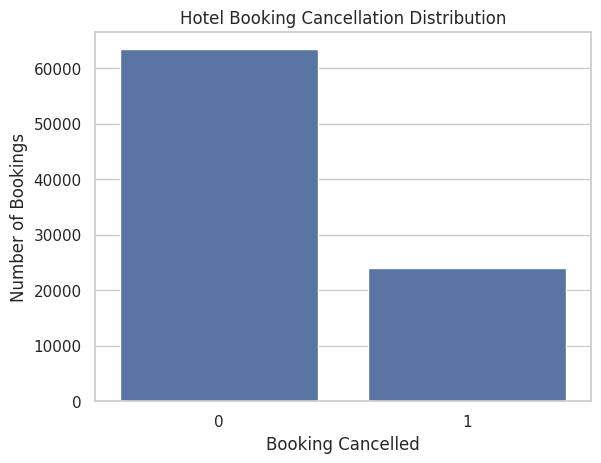

In [ ]:
sns.countplot(data=df, x='is_canceled')

plt.title('Hotel Booking Cancellation Distribution')
plt.xlabel('Booking Cancelled')
plt.ylabel('Number of Bookings')

plt.show()

## 5.1 Company Information and Cancellation


In [ ]:
df.groupby('is_canceled')['company'].apply(
    lambda x: x.notna().mean() * 100
)

,company
is_canceled,
0,7.392972
1,2.389178


In [ ]:
df['has_company'] = df['company'].notna().astype(int)

In [ ]:
df['has_company'].value_counts()

,count
has_company,
0,82137
1,5259


In [ ]:
df.groupby('has_company')['is_canceled'].mean() * 100

,is_canceled
has_company,
0,28.551079
1,10.914623


Company-associated bookings had a considerably lower cancellation rate (10.9%) than bookings without company information (28.6%), suggesting that corporate bookings may represent a more reliable demand segment.

What factors are associated with hotel booking cancellations?

## 5.2 Travel Agent Information and Cancellation


In [ ]:
df['agent'].value_counts(dropna=False).head(10)

,count
agent,
9.0,28759
240.0,13028
NaN,12193
14.0,3349
7.0,3300
250.0,2779
241.0,1644
28.0,1502
8.0,1383


In [ ]:
df['agent'].isna().sum()

np.int64(12193)

Do bookings associated with a travel agent have different cancellation behavior from bookings without agent information?

In [ ]:
df['has_agent'] = df['agent'].notna().astype(int)

Agent-associated bookings showed a higher cancellation rate (29.9%) than bookings without recorded agent information (12.8%), indicating that agent-mediated reservations may require closer cancellation-risk monitoring.

## 5.3 Customer Country and Cancellation


Does the customer's country relate to hotel booking cancellations, and which countries generate the most bookings?

In [ ]:
df['country'].isna().sum()

np.int64(0)

In [ ]:
df['country'] = df['country'].fillna('Unknown')

In [ ]:
df['country'].isna().sum()

np.int64(0)

In [ ]:
df['country'].value_counts().head(10)

,count
country,
PRT,27453
GBR,10433
FRA,8837
ESP,7252
DEU,5387
ITA,3066
IRL,3016
BEL,2081
BRA,1995


Portugal was the largest source market with 27,453 bookings, followed by the UK (10,433), France (8,837), and Spain (7,252). The strong concentration of bookings across European markets suggests that these regions are key customer markets for the hotels in the dataset.

In [ ]:
top_countries = df['country'].value_counts().head(10).index

df[df['country'].isin(top_countries)].groupby('country')['is_canceled'].mean().sort_values(ascending=False) * 100

,is_canceled
country,
BRA,36.441103
PRT,35.664590
ITA,35.061970
ESP,25.675676
IRL,22.148541
BEL,19.750120
FRA,19.610728
DEU,19.547058
GBR,19.026167


Cancellation behavior varies considerably across customer markets. Brazil (36.4%), Portugal (35.7%), and Italy (35.1%) recorded the highest cancellation rates among the top 10 markets, while the Netherlands (18.3%), UK (19.0%), and Germany (19.5%) showed substantially lower rates. This suggests that customer geography may be an important factor to consider when developing targeted cancellation-risk strategies.

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.shape

(87396, 34)

In [ ]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,has_company,has_agent
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,0,0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,0,0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,0,0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,0,1
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03,0,1


In [ ]:
df['hotel'].value_counts()

,count
hotel,
City Hotel,53428
Resort Hotel,33968


In [ ]:
print(df.shape)

print(df['hotel'].value_counts())

print(df['hotel'].unique())

(87396, 34)
hotel
City Hotel      53428
Resort Hotel    33968
Name: count, dtype: int64
['Resort Hotel' 'City Hotel']


## 5.4 Hotel Type and Cancellation


Does cancellation behavior differ between City Hotel and Resort Hotel?

In [ ]:
hotel_cancellation = df.groupby('hotel')['is_canceled'].mean() * 100

hotel_cancellation

,is_canceled
hotel,
City Hotel,30.038557
Resort Hotel,23.480923


City Hotel bookings had a higher cancellation rate (30.0%) than Resort Hotel bookings (23.5%), a difference of approximately 6.6 percentage points. This suggests that cancellation behavior differs by hotel type, and City Hotel may require greater attention to cancellation-risk management.

## 5.5 Lead Time and Cancellation


In [ ]:
#Does booking far in advance relate to cancellations?

In [ ]:
df.groupby('is_canceled')['lead_time'].mean()

,lead_time
is_canceled,
0,70.099588
1,105.719251


Cancelled bookings had a substantially higher average lead time (105.7 days) than non-cancelled bookings (70.1 days). This suggests that bookings made further in advance may be associated with a higher likelihood of cancellation.

In [ ]:
df['lead_time_group'] = pd.cut(
    df['lead_time'],
    bins=[0, 30, 60, 120, 180, 365, float('inf')],
    labels=['0-30 days', '31-60 days', '61-120 days',
            '121-180 days', '181-365 days', '365+ days']
)

In [ ]:
lead_time_cancellation = df.groupby(
    'lead_time_group',
    observed=True
)['is_canceled'].mean() * 100

lead_time_cancellation

,is_canceled
lead_time_group,
0-30 days,18.610898
31-60 days,31.621500
61-120 days,33.541980
121-180 days,35.091701
181-365 days,39.678571
365+ days,40.884956


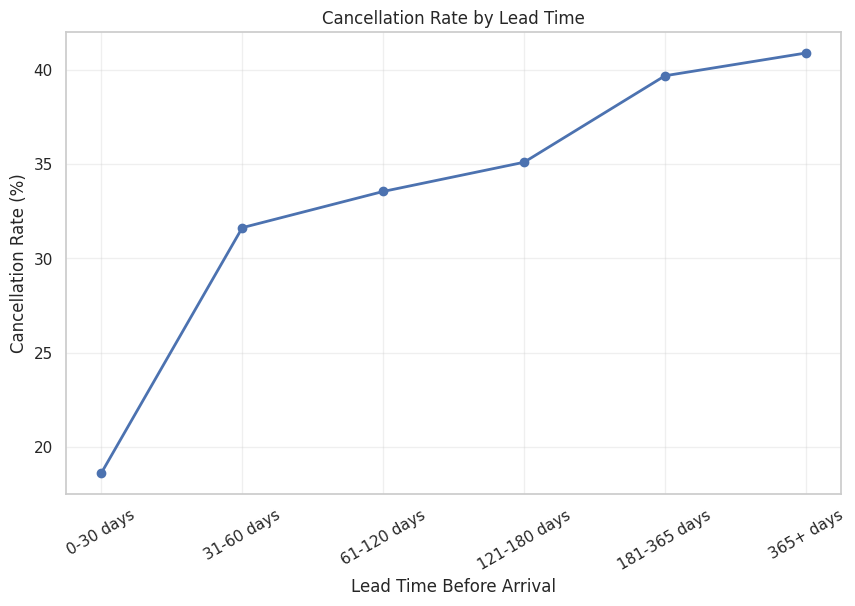

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    lead_time_cancellation.index,
    lead_time_cancellation.values,
    marker='o',
    linewidth=2
)

plt.title('Cancellation Rate by Lead Time')
plt.xlabel('Lead Time Before Arrival')
plt.ylabel('Cancellation Rate (%)')

plt.xticks(rotation=30)
plt.grid(True, alpha=0.3)

plt.show()

Cancellation rates increased substantially with longer lead times. Bookings made 0–30 days before arrival had an 18.6% cancellation rate, while bookings made more than 365 days in advance had a 40.9% cancellation rate. This indicates that long-lead-time bookings may represent a higher cancellation-risk segment and could benefit from stronger confirmation or cancellation-management strategies.   i need a graph also

## 5.6 ADR and Special Requests


Is the Average Daily Rate (ADR) associated with booking cancellations?

In [ ]:
df.groupby('is_canceled')['adr'].mean()

,adr
is_canceled,
0,102.001961
1,117.772476


Cancelled bookings had a higher average daily rate (ADR) of 117.77 compared with 102.00 for non-cancelled bookings. This suggests that higher-priced bookings may be associated with a greater likelihood of cancellation. However, ADR alone does not establish that higher prices cause cancellations.

In [ ]:
df.groupby('is_canceled')['total_of_special_requests'].mean()

,total_of_special_requests
is_canceled,
0,0.760316
1,0.535692


In [ ]:
import plotly.express as px

status = ['Not Cancelled', 'Cancelled']
requests = [0.760316, 0.535692]

fig = px.bar(
    x=status,
    y=requests,
    text=requests,
    title='Average Special Requests by Cancellation Status',
    labels={
        'x': 'Booking Status',
        'y': 'Average Special Requests'
    }
)

fig.update_traces(
    texttemplate='%{text:.2f}',
    textposition='outside'
)

fig.update_layout(
    width=800,
    height=500
)

fig.show()

Non-cancelled bookings had a higher average number of special requests (0.76) compared with cancelled bookings (0.54). This suggests that customers making more special requests may be more engaged with their reservations and less likely to cancel.

## 5.7 Repeated Guests and Cancellation


Are repeated guests less likely to cancel their bookings?

Your result:

In [ ]:
df.groupby('is_repeated_guest')['is_canceled'].mean() * 100

,is_canceled
is_repeated_guest,
0,28.296877
1,7.642753


In [ ]:
import plotly.express as px

guest_type = ['Non-Repeated Guest', 'Repeated Guest']
cancellation_rate = [28.296877, 7.642753]

fig = px.bar(
    x=guest_type,
    y=cancellation_rate,
    text=cancellation_rate,
    title='Cancellation Rate by Guest Type',
    labels={
        'x': 'Guest Type',
        'y': 'Cancellation Rate (%)'
    }
)

fig.update_traces(
    texttemplate='%{text:.2f}%',
    textposition='outside'
)

fig.update_layout(
    width=800,
    height=500
)

fig.show()

Repeated guests showed substantially lower cancellation rates (7.6%) compared with non-repeated guests (28.3%). This suggests that returning customers are a more reliable booking segment and may have stronger commitment to their reservations.

## 5.8 Customer Type and Cancellation


Does the type of customer affect the likelihood of cancellation?

In [ ]:
df.groupby('customer_type')['is_canceled'].mean() * 100

,is_canceled
customer_type,
Contract,16.310927
Group,9.926471
Transient,30.105854
Transient-Party,15.238339


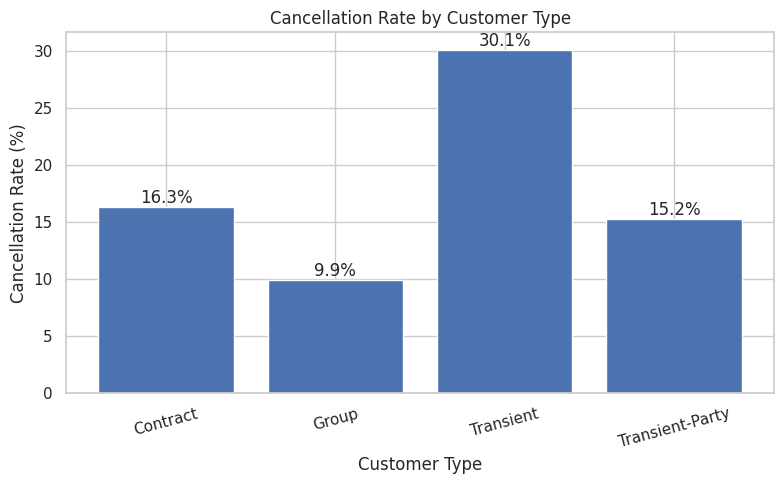

In [ ]:
customer_cancellation = df.groupby('customer_type')['is_canceled'].mean() * 100

plt.figure(figsize=(8, 5))

bars = plt.bar(
    customer_cancellation.index,
    customer_cancellation.values
)

plt.title('Cancellation Rate by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Cancellation Rate (%)')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.1f}%',
        ha='center',
        va='bottom'
    )

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Cancellation rates varied substantially across customer types. Transient bookings had the highest cancellation rate (30.1%), while Group bookings had the lowest (9.9%). This suggests that customer type is an important factor associated with booking cancellations, with transient bookings representing a relatively higher-risk segment.

## 5.9 Deposit Type and Cancellation


In [ ]:
df.groupby('deposit_type')['is_canceled'].mean() * 100

,is_canceled
deposit_type,
No Deposit,26.684908
Non Refund,94.701349
Refundable,24.299065


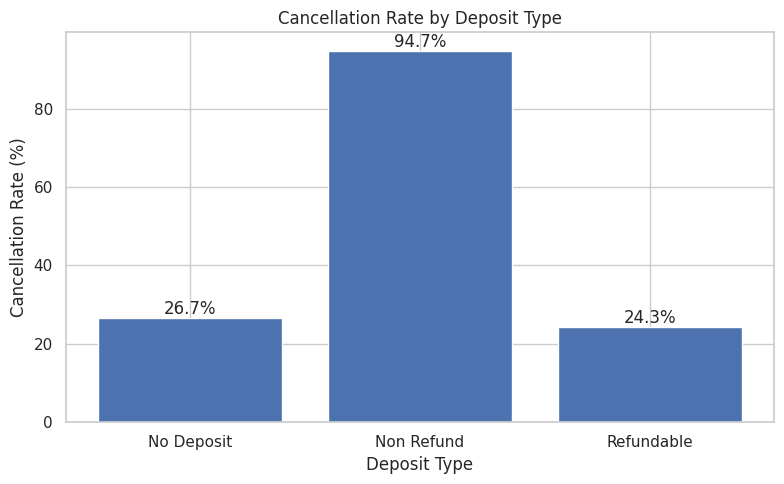

In [ ]:
deposit_cancellation = df.groupby('deposit_type')['is_canceled'].mean() * 100

plt.figure(figsize=(8, 5))

bars = plt.bar(
    deposit_cancellation.index,
    deposit_cancellation.values
)

plt.title('Cancellation Rate by Deposit Type')
plt.xlabel('Deposit Type')
plt.ylabel('Cancellation Rate (%)')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

Deposit type shows a very strong association with cancellation behavior. Non-refundable bookings had an exceptionally high cancellation rate of 94.7%, compared with 26.7% for bookings with no deposit and 24.3% for refundable bookings. This makes deposit type an important factor to investigate when assessing cancellation risk.

## 5.10 Market Segment and Cancellation


In [ ]:
#Does the market segment affect the likelihood of a booking being cancelled?

In [ ]:
df.groupby('market_segment')['is_canceled'].mean() * 100

,is_canceled
market_segment,
Aviation,19.823789
Complementary,12.535613
Corporate,12.108262
Direct,14.715351
Groups,27.013355
Offline TA/TO,14.853481
Online TA,35.346197
Undefined,100.000000


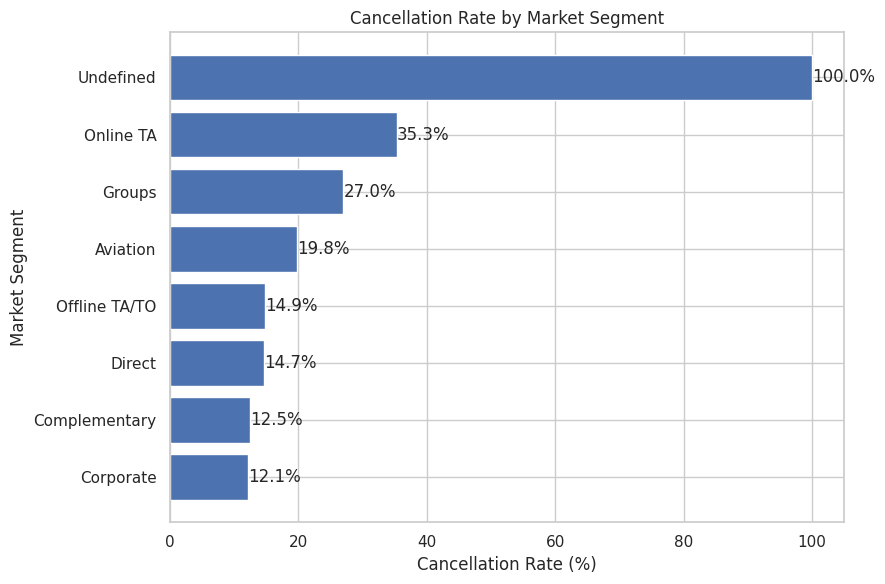

In [ ]:
market_cancellation = (
    df.groupby('market_segment')['is_canceled'].mean() * 100
).sort_values()

plt.figure(figsize=(9, 6))

bars = plt.barh(
    market_cancellation.index,
    market_cancellation.values
)

plt.title('Cancellation Rate by Market Segment')
plt.xlabel('Cancellation Rate (%)')
plt.ylabel('Market Segment')

for bar in bars:
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f'{bar.get_width():.1f}%',
        va='center',
        ha='left'
    )

plt.tight_layout()
plt.show()

Cancellation rates varied across market segments. Online TA bookings had the highest cancellation rate among the major segments at 35.3%, while Corporate bookings had a much lower rate of 12.1%. This suggests that market segment is associated with cancellation behavior and that online travel-agent bookings may require closer cancellation-risk monitoring.

## 5.11 Distribution Channel and Cancellation


In [ ]:
#Does the distribution channel through which a booking was made affect its cancellation likelihood?

In [ ]:
df.groupby('distribution_channel')['is_canceled'].mean() * 100

,is_canceled
distribution_channel,
Corporate,12.753395
Direct,14.821374
GDS,19.889503
TA/TO,30.968600
Undefined,80.000000


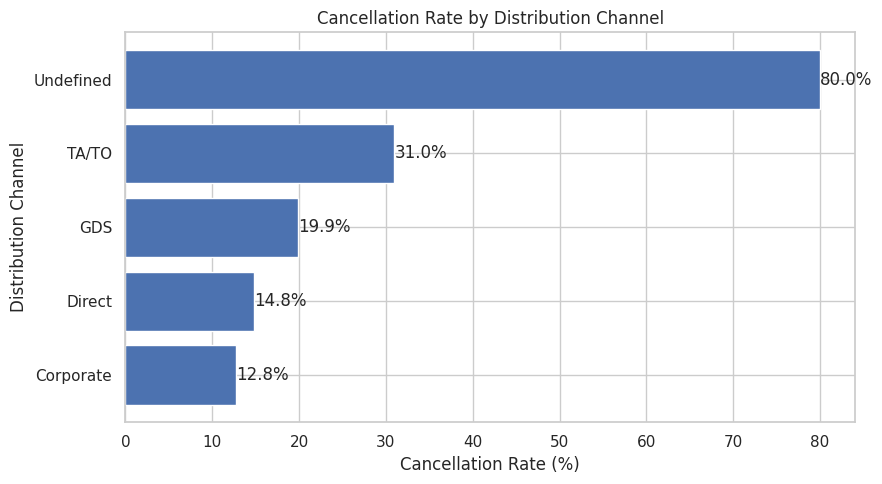

In [ ]:
channel_cancellation = (
    df.groupby('distribution_channel')['is_canceled'].mean() * 100
).sort_values()

plt.figure(figsize=(9, 5))

bars = plt.barh(
    channel_cancellation.index,
    channel_cancellation.values
)

plt.title('Cancellation Rate by Distribution Channel')
plt.xlabel('Cancellation Rate (%)')
plt.ylabel('Distribution Channel')

for bar in bars:
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f'{bar.get_width():.1f}%',
        va='center',
        ha='left'
    )

plt.tight_layout()
plt.show()

Cancellation rates varied across distribution channels. TA/TO bookings had a relatively high cancellation rate of 31.0%, compared with 12.8% for Corporate bookings. This suggests that distribution channel is associated with cancellation behavior and may be useful for identifying higher-risk booking sources.

## 5.12 Previous Cancellation History


Does a customer's previous cancellation history relate to their likelihood of cancelling again?

In [ ]:
df.groupby('previous_cancellations')['is_canceled'].mean() * 100

,is_canceled
previous_cancellations,
0,26.695523
1,76.119403
2,30.357143
3,26.229508
4,20.000000
5,10.526316
6,11.764706
11,7.407407
13,75.000000


In [ ]:
df['previous_cancellation_group'] = pd.cut(
    df['previous_cancellations'],
    bins=[-1, 0, 1, 5, float('inf')],
    labels=['0', '1', '2-5', '6+']
)

previous_cancel_rate = (
    df.groupby('previous_cancellation_group', observed=True)['is_canceled'].mean() * 100
)

previous_cancel_rate

,is_canceled
previous_cancellation_group,
0,26.695523
1,76.119403
2-5,26.126126
6+,26.785714


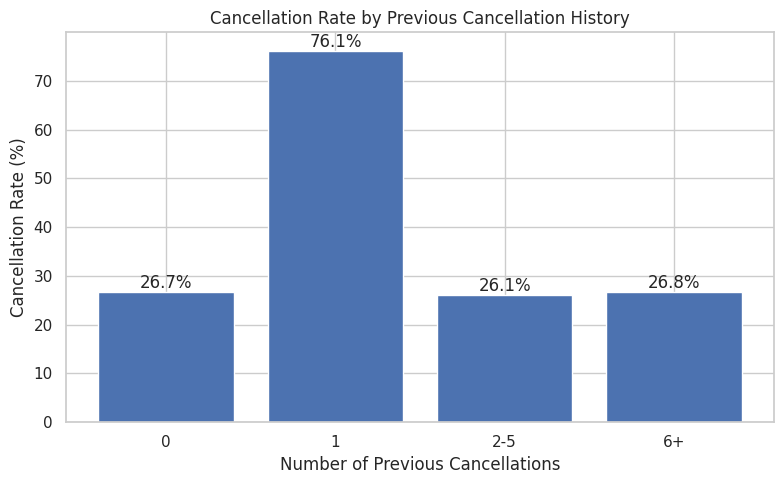

In [ ]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    previous_cancel_rate.index.astype(str),
    previous_cancel_rate.values
)

plt.title('Cancellation Rate by Previous Cancellation History')
plt.xlabel('Number of Previous Cancellations')
plt.ylabel('Cancellation Rate (%)')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

Customers with exactly one previous cancellation had a substantially higher cancellation rate (76.1%) than customers with no previous cancellations (26.7%). However, customers with 2–5 or 6+ previous cancellations had cancellation rates around 26%, indicating that previous cancellation history does not show a consistent increasing trend in this dataset.

## 5.13 Previous Successful Bookings


In [ ]:
#Are customers with previous successful bookings less likely to cancel?

In [ ]:
df.groupby('previous_bookings_not_canceled')['is_canceled'].mean() * 100

,is_canceled
previous_bookings_not_canceled,
0,28.440925
1,4.453441
2,5.517241
3,5.135952
4,5.263158
...,...
68,0.000000
69,0.000000
70,0.000000


In [ ]:
df['previous_bookings_group'] = pd.cut(
    df['previous_bookings_not_canceled'],
    bins=[-1, 0, 1, 5, float('inf')],
    labels=['0', '1', '2-5', '6+']
)

previous_bookings_rate = (
    df.groupby('previous_bookings_group', observed=True)['is_canceled'].mean() * 100
)

previous_bookings_rate

,is_canceled
previous_bookings_group,
0,28.440925
1,4.453441
2-5,5.454545
6+,5.248991


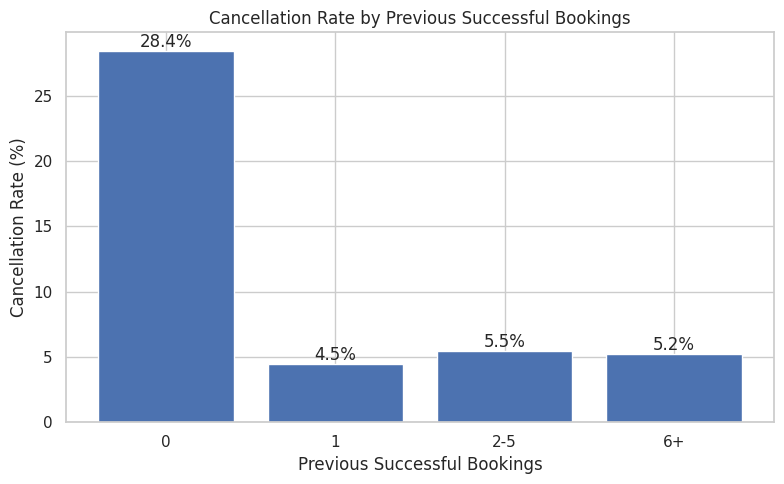

In [ ]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    previous_bookings_rate.index.astype(str),
    previous_bookings_rate.values
)

plt.title('Cancellation Rate by Previous Successful Bookings')
plt.xlabel('Previous Successful Bookings')
plt.ylabel('Cancellation Rate (%)')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

## 5.14 Booking Changes


In [ ]:
#Does the number of booking changes have any relationship with cancellation?

In [ ]:
df.groupby('booking_changes')['is_canceled'].mean() * 100

,is_canceled
booking_changes,
0,30.167567
1,13.859842
2,20.068415
3,14.971429
4,17.696629
5,17.241379
6,28.813559
7,9.677419
8,23.529412


In [ ]:
df['booking_changes_group'] = pd.cut(
    df['booking_changes'],
    bins=[-1, 0, 1, 3, 5, float('inf')],
    labels=['0', '1', '2-3', '4-5', '6+']
)

booking_changes_rate = (
    df.groupby('booking_changes_group', observed=True)['is_canceled'].mean() * 100
)

booking_changes_rate

,is_canceled
booking_changes_group,
0,30.167567
1,13.859842
2-3,19.050878
4-5,17.584746
6+,19.310345


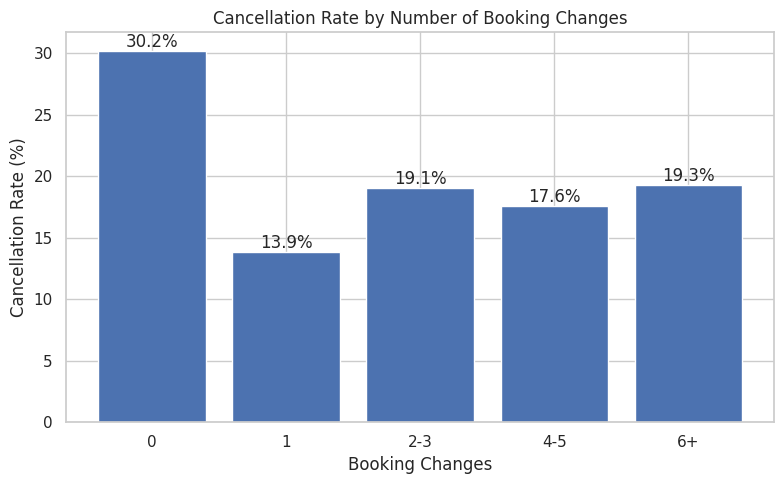

In [ ]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    booking_changes_rate.index.astype(str),
    booking_changes_rate.values
)

plt.title('Cancellation Rate by Number of Booking Changes')
plt.xlabel('Booking Changes')
plt.ylabel('Cancellation Rate (%)')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

Bookings with no changes had a higher cancellation rate (30.2%) than bookings that underwent at least one change. However, cancellation rates remained relatively stable across higher booking-change groups, ranging from approximately 17.6% to 19.3%. This suggests that the number of booking changes does not show a clear increasing relationship with cancellation in this dataset.

## 5.15 Parking Requirements


Are bookings that request more parking spaces more or less likely to be cancelled?

In [ ]:
df.groupby('required_car_parking_spaces')['is_canceled'].mean() * 100

,is_canceled
required_car_parking_spaces,
0,30.000125
1,0.000000
2,0.000000
3,0.000000
8,0.000000


In [ ]:
df['required_car_parking_spaces'].value_counts().sort_index()

,count
required_car_parking_spaces,
0,80083
1,7280
2,28
3,3
8,2


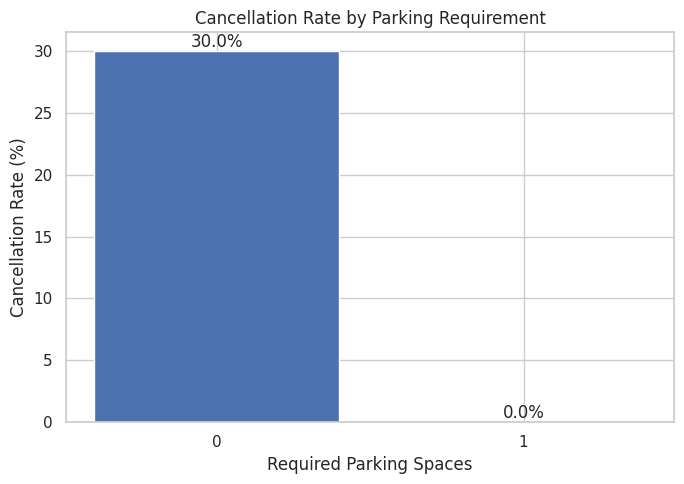

In [ ]:
parking_rate = (
    df[df['required_car_parking_spaces'].isin([0, 1])]
    .groupby('required_car_parking_spaces')['is_canceled']
    .mean() * 100
)

plt.figure(figsize=(7, 5))

bars = plt.bar(
    parking_rate.index.astype(str),
    parking_rate.values
)

plt.title('Cancellation Rate by Parking Requirement')
plt.xlabel('Required Parking Spaces')
plt.ylabel('Cancellation Rate (%)')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

Bookings requesting one parking space had a much lower cancellation rate than bookings requesting no parking space (0.0% vs. 30.0%). However, this should be interpreted as an association rather than evidence that requesting parking reduces cancellations.

## 5.16 Waiting List Duration


In [ ]:
df.groupby('days_in_waiting_list')['is_canceled'].mean() * 100

,is_canceled
days_in_waiting_list,
0,27.423269
1,25.000000
2,20.000000
3,100.000000
4,13.333333
...,...
236,14.285714
259,0.000000
330,25.000000


In [ ]:
df['waiting_list_group'] = pd.cut(
    df['days_in_waiting_list'],
    bins=[-1, 0, 7, 30, 90, float('inf')],
    labels=['0 days', '1-7 days', '8-30 days', '31-90 days', '90+ days']
)

waiting_list_rate = (
    df.groupby('waiting_list_group', observed=True)['is_canceled'].mean() * 100
)

waiting_list_rate

,is_canceled
waiting_list_group,
0 days,27.423269
1-7 days,29.090909
8-30 days,49.305556
31-90 days,33.576642
90+ days,27.600000


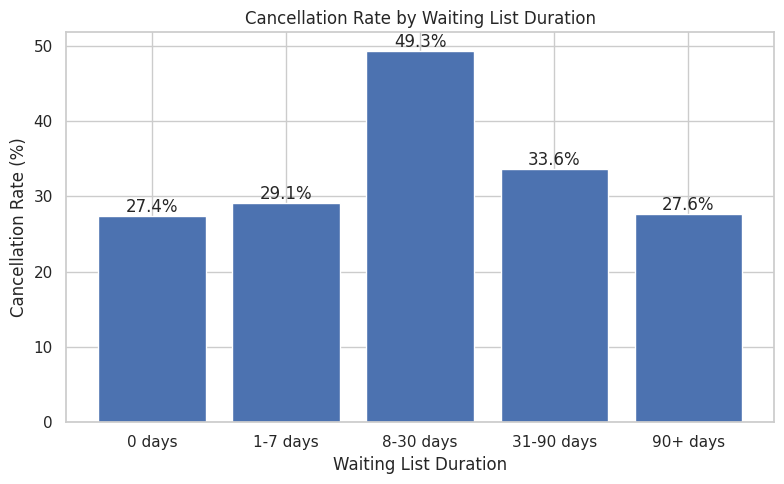

In [ ]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    waiting_list_rate.index.astype(str),
    waiting_list_rate.values
)

plt.title('Cancellation Rate by Waiting List Duration')
plt.xlabel('Waiting List Duration')
plt.ylabel('Cancellation Rate (%)')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

Cancellation rates varied across waiting-list groups, with bookings waiting 8–30 days showing the highest cancellation rate at 49.3%. The rate was lower for both shorter and longer waiting periods, indicating that waiting-list duration is associated with cancellation behavior but does not show a simple increasing relationship with cancellation.

## 5.17 Total Stay Duration


In [ ]:
df['total_stay_nights'] = (
    df['stays_in_weekend_nights'] +
    df['stays_in_week_nights']
)

In [ ]:
df.groupby('total_stay_nights')['is_canceled'].mean() * 100

,is_canceled
total_stay_nights,
0,4.454685
1,18.395019
2,26.706891
3,29.979259
4,30.497238
5,30.376743
6,34.484867
7,30.676232
8,37.394564


In [ ]:
df['stay_length_group'] = pd.cut(
    df['total_stay_nights'],
    bins=[-1, 1, 3, 5, 7, 14, float('inf')],
    labels=[
        '0-1 nights',
        '2-3 nights',
        '4-5 nights',
        '6-7 nights',
        '8-14 nights',
        '15+ nights'
    ]
)

stay_length_rate = (
    df.groupby('stay_length_group', observed=True)['is_canceled'].mean() * 100
)

stay_length_rate

,is_canceled
stay_length_group,
0-1 nights,17.886179
2-3 nights,28.445093
4-5 nights,30.457253
6-7 nights,31.829969
8-14 nights,32.664884
15+ nights,51.069519


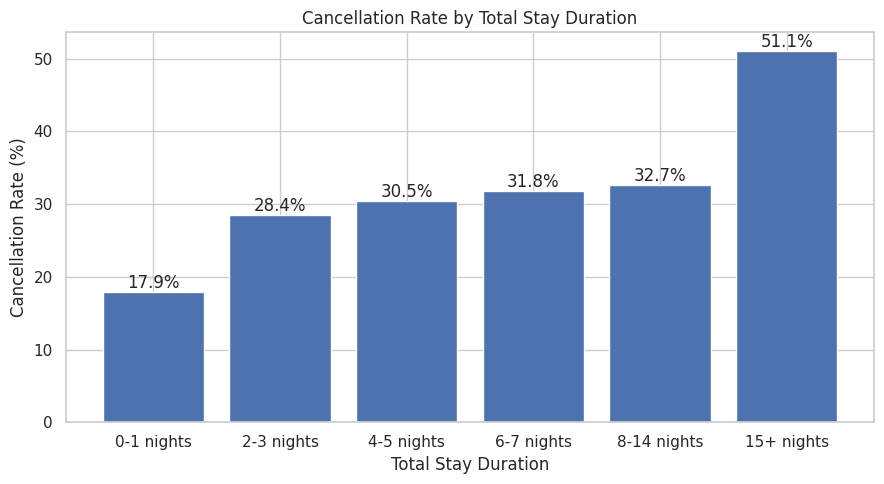

In [ ]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    stay_length_rate.index.astype(str),
    stay_length_rate.values
)

plt.title('Cancellation Rate by Total Stay Duration')
plt.xlabel('Total Stay Duration')
plt.ylabel('Cancellation Rate (%)')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

Cancellation rates generally increased with planned stay duration. Very short stays of 0–1 nights had a cancellation rate of 17.9%, while bookings for 15 or more nights had a substantially higher rate of 51.1%. This suggests that longer planned stays are associated with greater cancellation risk in the dataset.

## 5.18 Number of Adults


Does the number of adults in a booking relate to cancellation behavior?

In [ ]:
df.groupby('adults')['is_canceled'].mean() * 100

,is_canceled
adults,
0,25.194805
1,19.444949
2,28.933129
3,34.170177
4,23.333333
5,100.000000
6,100.000000
10,100.000000
20,100.000000


In [ ]:
df['adults_group'] = pd.cut(
    df['adults'],
    bins=[-1, 1, 2, 3, float('inf')],
    labels=['0-1 adults', '2 adults', '3 adults', '4+ adults']
)

adults_cancellation_rate = (
    df.groupby('adults_group', observed=True)['is_canceled'].mean() * 100
)

adults_cancellation_rate

,is_canceled
adults_group,
0-1 adults,19.576030
2 adults,28.933129
3 adults,34.170177
4+ adults,39.473684


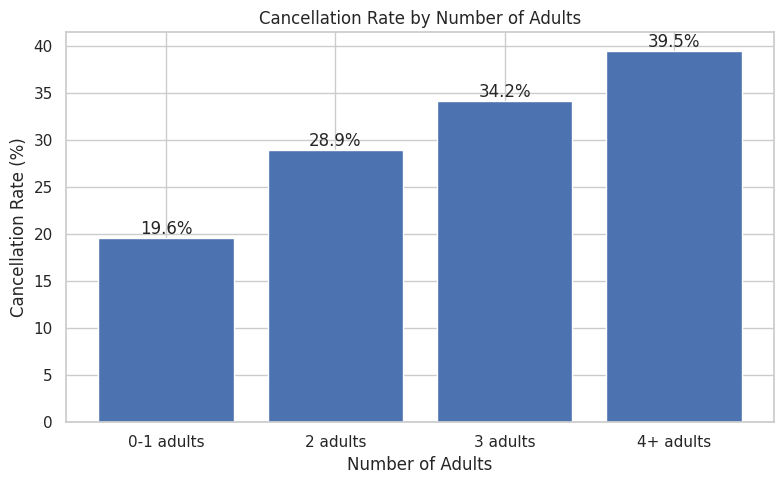

In [ ]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    adults_cancellation_rate.index.astype(str),
    adults_cancellation_rate.values
)

plt.title('Cancellation Rate by Number of Adults')
plt.xlabel('Number of Adults')
plt.ylabel('Cancellation Rate (%)')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

Cancellation rates increased with the number of adults in a booking. Bookings with 0–1 adults had a cancellation rate of 19.6%, compared with 39.5% for bookings with 4 or more adults. This suggests that larger adult groups may represent a higher cancellation-risk segment.

## 5.19 Number of Children


In [ ]:
df.groupby('children')['is_canceled'].mean() * 100

,is_canceled
children,
0.0,26.618414
1.0,31.203408
2.0,41.831339
3.0,21.333333
10.0,100.000000


In [ ]:
df['children'].value_counts().sort_index()

,count
children,
0.0,79028
1.0,4695
2.0,3593
3.0,75
10.0,1


In [ ]:
df['children_group'] = pd.cut(
    df['children'],
    bins=[-1, 0, 1, float('inf')],
    labels=['0 children', '1 child', '2+ children']
)

children_cancellation_rate = (
    df.groupby('children_group', observed=True)['is_canceled'].mean() * 100
)

children_cancellation_rate

,is_canceled
children_group,
0 children,26.618414
1 child,31.203408
2+ children,41.428182


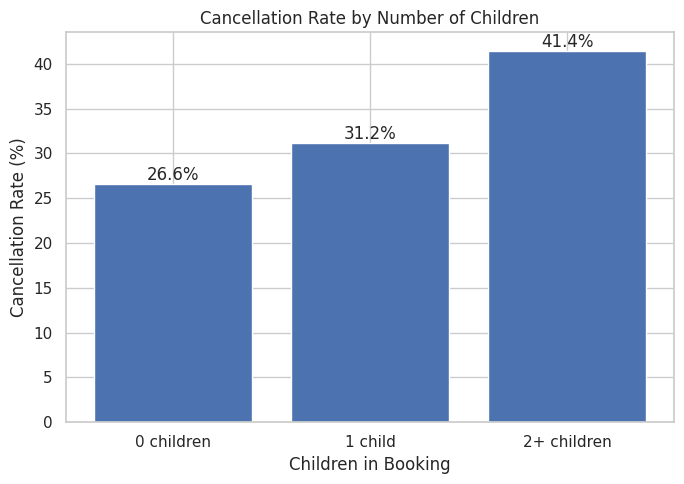

In [ ]:
plt.figure(figsize=(7, 5))

bars = plt.bar(
    children_cancellation_rate.index.astype(str),
    children_cancellation_rate.values
)

plt.title('Cancellation Rate by Number of Children')
plt.xlabel('Children in Booking')
plt.ylabel('Cancellation Rate (%)')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

Cancellation rates increased with the number of children in the booking. Bookings with no children had a cancellation rate of 26.6%, compared with 41.4% for bookings with two or more children. This suggests that bookings involving larger child groups may represent a higher cancellation-risk segment.

## 5.20 Number of Babies


In [ ]:
df.groupby('babies')['is_canceled'].mean() * 100

,is_canceled
babies,
0,27.587244
1,18.394649
2,13.333333
9,0.000000
10,0.000000


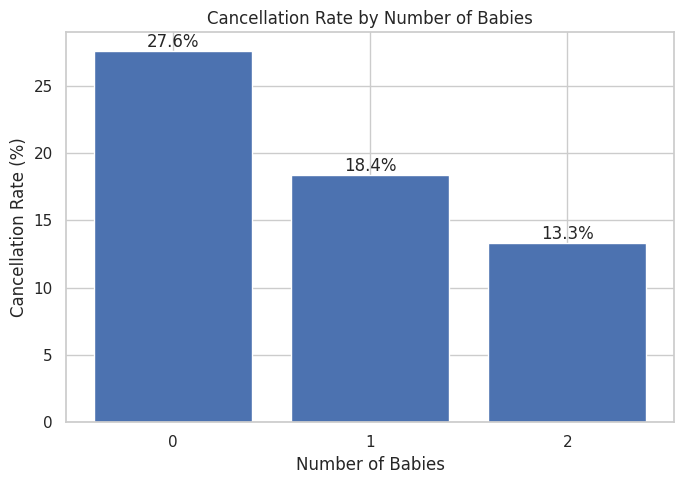

In [ ]:
babies_rate = (
    df[df['babies'].isin([0, 1, 2])]
    .groupby('babies')['is_canceled']
    .mean() * 100
)

plt.figure(figsize=(7, 5))

bars = plt.bar(
    babies_rate.index.astype(str),
    babies_rate.values
)

plt.title('Cancellation Rate by Number of Babies')
plt.xlabel('Number of Babies')
plt.ylabel('Cancellation Rate (%)')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

Bookings involving babies showed lower cancellation rates than bookings without babies. The cancellation rate was 27.6% for bookings with no babies, compared with 18.4% for one baby and 13.3% for two babies. However, the baby-related categories are relatively small, so this relationship should be interpreted cautiously.

## 5.21 Room Type Changes


In [ ]:
#Does getting a different room type from the one originally reserved relate to cancellation?

In [ ]:
df['room_type_changed'] = (
    df['reserved_room_type'] != df['assigned_room_type']
).astype(int)

In [ ]:
df.groupby('room_type_changed')['is_canceled'].mean() * 100

,is_canceled
room_type_changed,
0,31.510224
1,4.706690


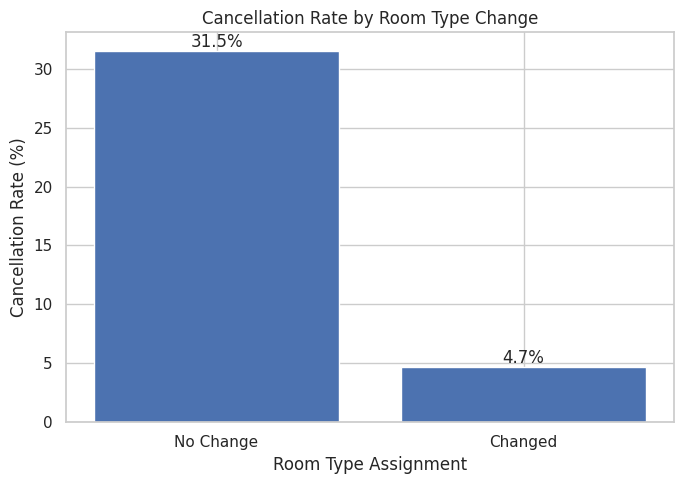

In [ ]:
room_change_rate = (
    df.groupby('room_type_changed')['is_canceled'].mean() * 100
)

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ['No Change', 'Changed'],
    room_change_rate.values
)

plt.title('Cancellation Rate by Room Type Change')
plt.xlabel('Room Type Assignment')
plt.ylabel('Cancellation Rate (%)')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

Bookings where the assigned room type differed from the reserved room type showed a substantially lower cancellation rate (4.7%) compared with bookings where the room type remained unchanged (31.5%). This indicates a strong association between room-type assignment changes and cancellation behavior.

## 5.22 Meal Type


In [ ]:
#Does the meal plan selected by a customer relate to the likelihood of cancellation?

In [ ]:
df.groupby('meal')['is_canceled'].mean() * 100

,is_canceled
meal,
BB,26.548295
FB,27.500000
HB,26.967529
SC,35.302183
Undefined,16.666667


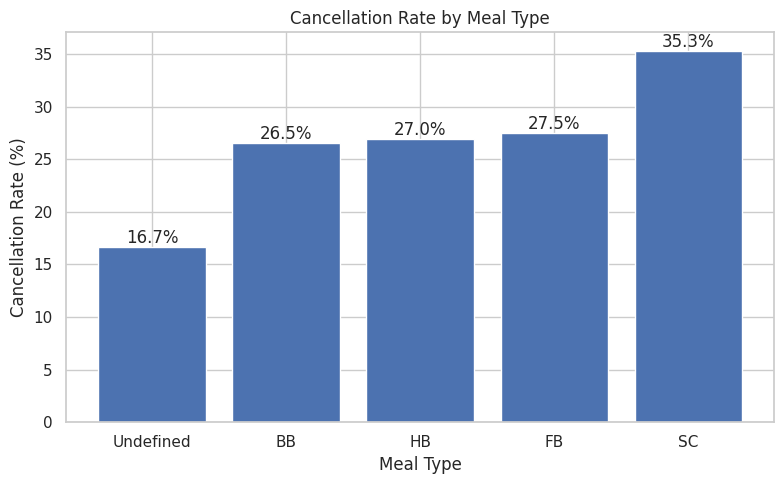

In [ ]:
meal_cancellation_rate = (
    df.groupby('meal')['is_canceled'].mean() * 100
).sort_values()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    meal_cancellation_rate.index,
    meal_cancellation_rate.values
)

plt.title('Cancellation Rate by Meal Type')
plt.xlabel('Meal Type')
plt.ylabel('Cancellation Rate (%)')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

Cancellation rates varied across meal types, with Self Catering (SC) bookings showing the highest cancellation rate at 35.3%. The other major meal types—BB, HB, and FB—had relatively similar cancellation rates of approximately 26.5–27.5%. This suggests that meal type is associated with cancellation behavior, although the relationship is not necessarily causal.

## 6. Bivariate Analysis


How do two variables interact, and does that reveal a deeper business pattern?”

## 6.1 Hotel Type × Lead Time


In [ ]:
#Does the relationship between lead time and cancellation differ between City Hotel and Resort Hotel?

In [ ]:
hotel_lead_cancellation = (
    df.groupby(
        ['hotel', 'lead_time_group'],
        observed=True
    )['is_canceled']
    .mean() * 100
)

hotel_lead_cancellation

hotel         lead_time_group
City Hotel    0-30 days          21.422050
              31-60 days         32.807749
              61-120 days        34.417685
              121-180 days       37.475901
              181-365 days       44.478475
              365+ days          51.329787
Resort Hotel  0-30 days          14.189553
              31-60 days         29.269926
              61-120 days        31.765992
              121-180 days       31.327558
              181-365 days       34.379110
              365+ days          20.105820
Name: is_canceled, dtype: float64

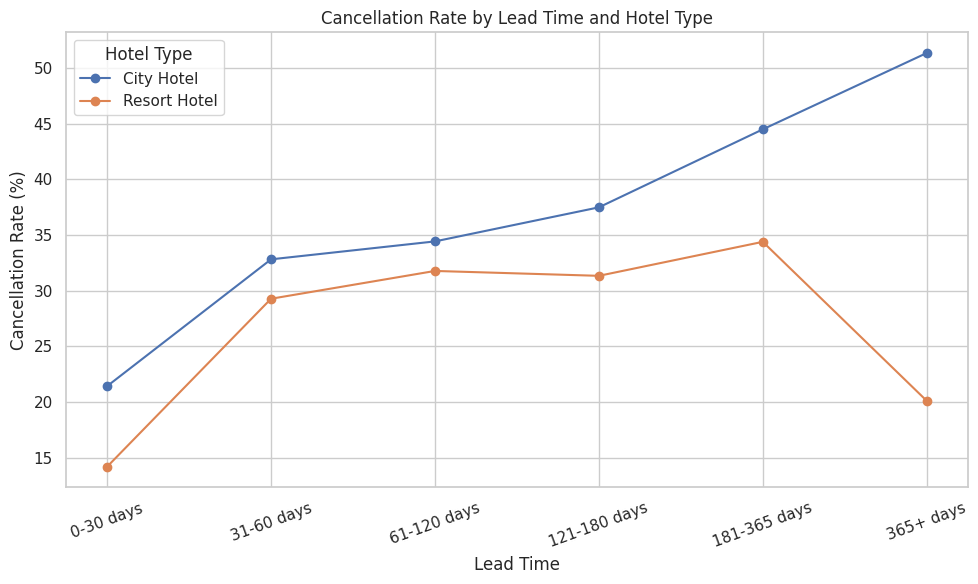

In [ ]:
hotel_lead_plot = hotel_lead_cancellation.reset_index()

plt.figure(figsize=(10, 6))

for hotel in hotel_lead_plot['hotel'].unique():
    hotel_data = hotel_lead_plot[
        hotel_lead_plot['hotel'] == hotel
    ]

    plt.plot(
        hotel_data['lead_time_group'].astype(str),
        hotel_data['is_canceled'],
        marker='o',
        label=hotel
    )

plt.title('Cancellation Rate by Lead Time and Hotel Type')
plt.xlabel('Lead Time')
plt.ylabel('Cancellation Rate (%)')
plt.legend(title='Hotel Type')
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

The relationship between lead time and cancellation differs by hotel type. City Hotel bookings show a strong increase in cancellation rates as lead time increases, reaching 51.3% for bookings made more than 365 days in advance. Resort Hotel bookings show a weaker and less consistent pattern, with the 365+ day group having a cancellation rate of 20.1%. This suggests that lead-time-based cancellation management may need to be tailored by hotel type.

## 6.2 Hotel Type × Market Segment


In [ ]:
#Does cancellation behavior across market segments differ between City Hotel and Resort Hotel?

In [ ]:
market_hotel_cancellation = (
    df.groupby(
        ['hotel', 'market_segment']
    )['is_canceled']
    .mean() * 100
)

market_hotel_cancellation

hotel         market_segment
City Hotel    Aviation           19.823789
              Complementary      11.111111
              Corporate          11.854513
              Direct             16.405828
              Groups             33.776091
              Offline TA/TO      17.342869
              Online TA          36.057610
              Undefined         100.000000
Resort Hotel  Complementary      16.402116
              Corporate          12.392947
              Direct             13.210568
              Groups             19.289120
              Offline TA/TO      12.118465
              Online TA          33.848653
Name: is_canceled, dtype: float64

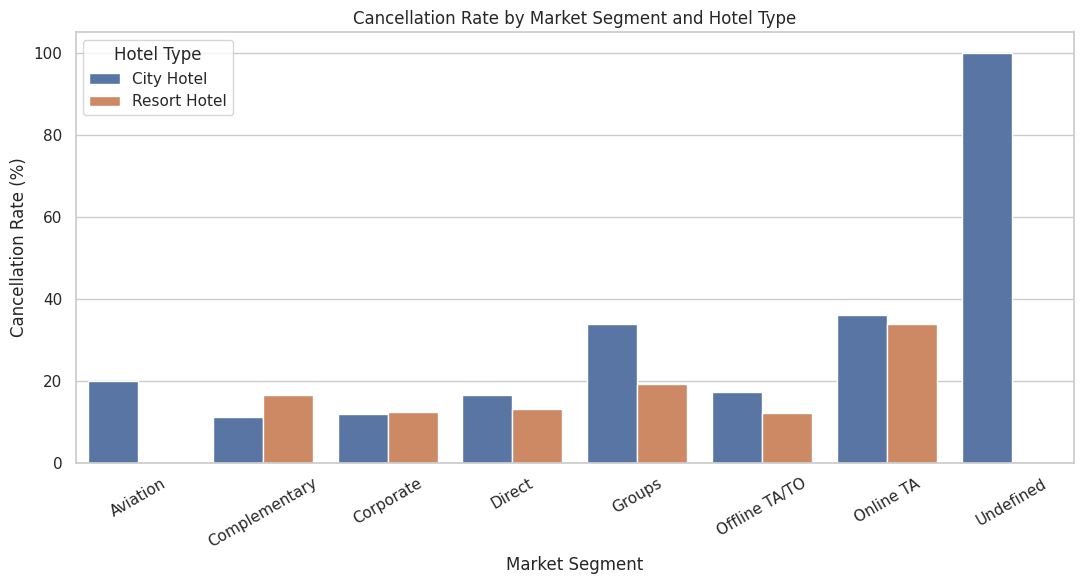

In [ ]:
market_hotel_plot = market_hotel_cancellation.reset_index()

plt.figure(figsize=(11, 6))

sns.barplot(
    data=market_hotel_plot,
    x='market_segment',
    y='is_canceled',
    hue='hotel'
)

plt.title('Cancellation Rate by Market Segment and Hotel Type')
plt.xlabel('Market Segment')
plt.ylabel('Cancellation Rate (%)')
plt.xticks(rotation=30)
plt.legend(title='Hotel Type')

plt.tight_layout()
plt.show()

Cancellation patterns across market segments differ by hotel type. Online TA bookings showed consistently high cancellation rates for both City Hotel (36.1%) and Resort Hotel (33.8%), while Group bookings showed a much higher cancellation rate at City Hotel (33.8%) than at Resort Hotel (19.3%). Corporate bookings had relatively low and similar cancellation rates across both hotel types. This suggests that cancellation-risk management may benefit from considering both market segment and hotel type together.

## 6.3 Hotel Type × ADR


In [ ]:
hotel_adr = df.groupby('hotel')['adr'].mean()

hotel_adr

,adr
hotel,
City Hotel,110.985944
Resort Hotel,99.025346


In [ ]:
hotel_adr_cancellation = (
    df.groupby(['hotel', 'is_canceled'])['adr']
    .mean()
)

hotel_adr_cancellation

hotel         is_canceled
City Hotel    0              108.284982
              1              117.276632
Resort Hotel  0               92.966370
              1              118.770194
Name: adr, dtype: float64

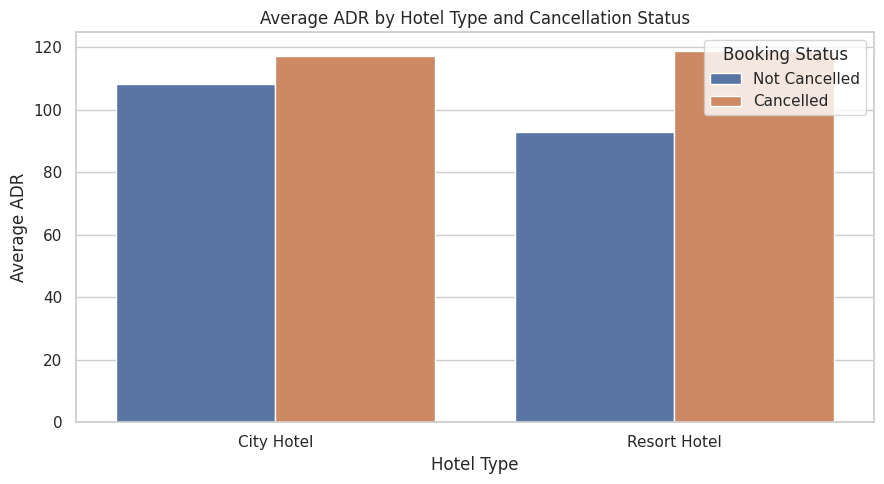

In [ ]:
adr_plot = (
    df.groupby(['hotel', 'is_canceled'])['adr']
    .mean()
    .reset_index()
)

adr_plot['is_canceled'] = adr_plot['is_canceled'].map({
    0: 'Not Cancelled',
    1: 'Cancelled'
})

plt.figure(figsize=(9, 5))

sns.barplot(
    data=adr_plot,
    x='hotel',
    y='adr',
    hue='is_canceled'
)

plt.title('Average ADR by Hotel Type and Cancellation Status')
plt.xlabel('Hotel Type')
plt.ylabel('Average ADR')
plt.legend(title='Booking Status')

plt.tight_layout()
plt.show()

ADR is associated with cancellation behavior across both hotel types. Cancelled bookings had higher average ADR than non-cancelled bookings for both City Hotel and Resort Hotel. The difference was particularly pronounced for Resort Hotel, where cancelled bookings had an average ADR of 118.77 compared with 92.97 for non-cancelled bookings. This suggests that higher-priced bookings may represent a higher cancellation-risk segment, although ADR alone does not establish causation.

## 6.4 Market Segment × Deposit Type


In [ ]:
deposit_market_cancellation = (
    df.groupby(
        ['market_segment', 'deposit_type']
    )['is_canceled']
    .mean() * 100
)

deposit_market_cancellation

market_segment  deposit_type
Aviation        No Deposit       19.823789
Complementary   No Deposit       12.535613
Corporate       No Deposit       11.194210
                Non Refund       70.312500
                Refundable       33.333333
Direct          No Deposit       14.658975
                Non Refund       70.000000
                Refundable       33.333333
Groups          No Deposit       16.559600
                Non Refund       95.902883
                Refundable        8.750000
Offline TA/TO   No Deposit       13.068098
                Non Refund       98.954704
                Refundable       50.000000
Online TA       No Deposit       35.311906
                Non Refund       83.333333
                Refundable      100.000000
Undefined       No Deposit      100.000000
Name: is_canceled, dtype: float64

In [ ]:
deposit_market_counts = (
    df.groupby(
        ['market_segment', 'deposit_type']
    ).size()
)

deposit_market_counts

market_segment  deposit_type
Aviation        No Deposit        227
Complementary   No Deposit        702
Corporate       No Deposit       4145
                Non Refund         64
                Refundable          3
Direct          No Deposit      11788
                Non Refund         10
                Refundable          6
Groups          No Deposit       4203
                Non Refund        659
                Refundable         80
Offline TA/TO   No Deposit      13598
                Non Refund        287
                Refundable          4
Online TA       No Deposit      51586
                Non Refund         18
                Refundable         14
Undefined       No Deposit          2
dtype: int64

## 6.5 Hotel Type × Stay Duration


In [ ]:
stay_hotel_cancellation = (
    df.groupby(
        ['hotel', 'stay_length_group'],
        observed=True
    )['is_canceled']
    .mean() * 100
)

stay_hotel_cancellation

hotel         stay_length_group
City Hotel    0-1 nights           21.897465
              2-3 nights           30.484903
              4-5 nights           31.543478
              6-7 nights           37.500000
              8-14 nights          51.022395
              15+ nights           73.248408
Resort Hotel  0-1 nights           12.047363
              2-3 nights           23.045178
              4-5 nights           28.157128
              6-7 nights           29.115311
              8-14 nights          27.217567
              15+ nights           35.023041
Name: is_canceled, dtype: float64

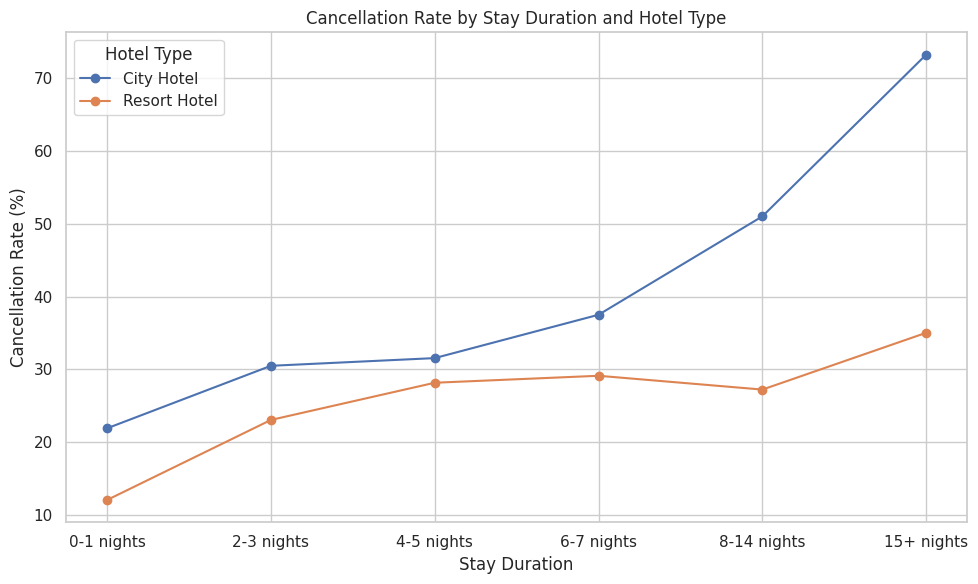

In [ ]:
stay_hotel_plot = stay_hotel_cancellation.reset_index()

plt.figure(figsize=(10, 6))

for hotel in stay_hotel_plot['hotel'].unique():
    hotel_data = stay_hotel_plot[
        stay_hotel_plot['hotel'] == hotel
    ]

    plt.plot(
        hotel_data['stay_length_group'].astype(str),
        hotel_data['is_canceled'],
        marker='o',
        label=hotel
    )

plt.title('Cancellation Rate by Stay Duration and Hotel Type')
plt.xlabel('Stay Duration')
plt.ylabel('Cancellation Rate (%)')
plt.legend(title='Hotel Type')

plt.tight_layout()
plt.show()

The association between stay duration and cancellation differs substantially by hotel type. City Hotel showed a strong increase in cancellation rates as planned stay duration increased, reaching 73.2% for bookings of 15 or more nights. Resort Hotel showed a weaker relationship, with a 35.0% cancellation rate for stays of 15 or more nights. This suggests that long-stay City Hotel bookings may represent a particularly high-risk segment for cancellation management.

## 6.6 Hotel Type × Customer Type


In [ ]:
#Does customer type have the same cancellation pattern in City Hotel and Resort Hotel?

In [ ]:
customer_hotel_cancellation = (
    df.groupby(
        ['hotel', 'customer_type']
    )['is_canceled']
    .mean() * 100
)

customer_hotel_cancellation

hotel         customer_type  
City Hotel    Contract           25.016995
              Group               8.856089
              Transient          32.423109
              Transient-Party    16.792051
Resort Hotel  Contract            8.633094
              Group              10.989011
              Transient          26.322911
              Transient-Party    12.900470
Name: is_canceled, dtype: float64

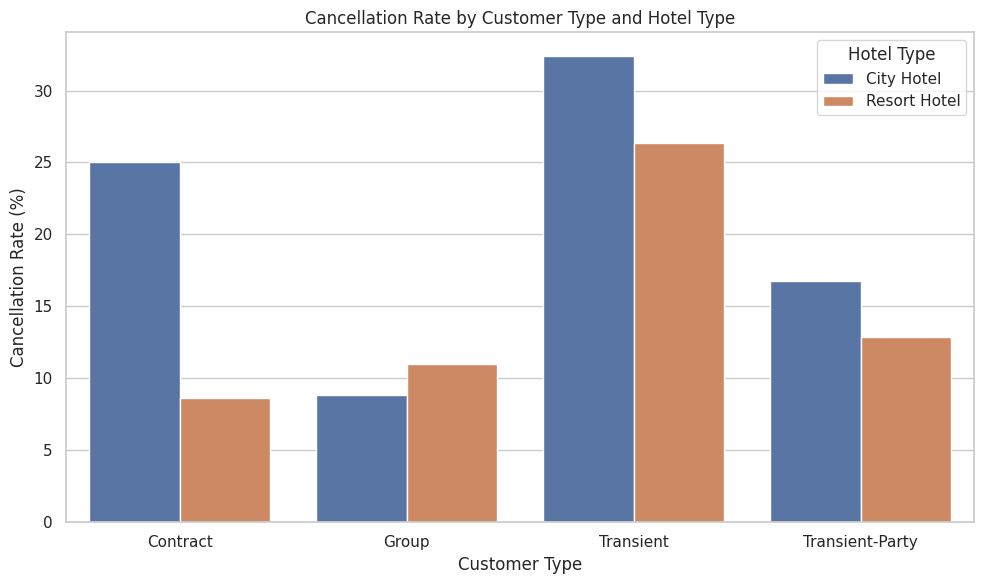

In [ ]:
customer_hotel_plot = (
    customer_hotel_cancellation
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=customer_hotel_plot,
    x='customer_type',
    y='is_canceled',
    hue='hotel'
)

plt.title('Cancellation Rate by Customer Type and Hotel Type')
plt.xlabel('Customer Type')
plt.ylabel('Cancellation Rate (%)')
plt.legend(title='Hotel Type')

plt.tight_layout()
plt.show()

Cancellation behavior varies by both customer type and hotel type. Transient customers showed the highest cancellation rates for both City Hotel (32.4%) and Resort Hotel (26.3%). Contract customers showed a much larger difference between hotel types, with cancellation rates of 25.0% at City Hotel compared with 8.6% at Resort Hotel. Group customers had relatively low cancellation rates at both hotels. This suggests that customer type and hotel type jointly provide useful information for understanding cancellation risk.

## 6.7 Previous Successful Bookings × Cancellation


In [ ]:
#Are customers with a history of successful bookings less likely to cancel?

In [ ]:
previous_bookings_cancellation = (
    df.groupby(
        'previous_bookings_group',
        observed=True
    )['is_canceled']
    .mean() * 100
)

previous_bookings_cancellation

,is_canceled
previous_bookings_group,
0,28.440925
1,4.453441
2-5,5.454545
6+,5.248991


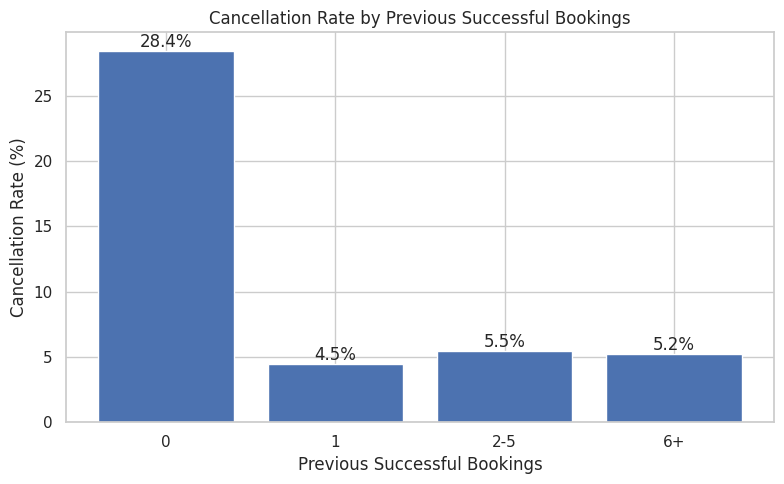

In [ ]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    previous_bookings_cancellation.index.astype(str),
    previous_bookings_cancellation.values
)

plt.title('Cancellation Rate by Previous Successful Bookings')
plt.xlabel('Previous Successful Bookings')
plt.ylabel('Cancellation Rate (%)')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

Customers with previous successful bookings were substantially less likely to cancel than customers with no previous successful booking history. Cancellation was 28.4% among customers with no previous successful bookings, compared with approximately 4–5.5% among customers with at least one previous successful booking. This suggests that established customers represent a considerably more reliable booking segment.

## 7. Statistical Hypothesis Testing


In [ ]:
contingency_table = pd.crosstab(
    df['customer_type'],
    df['is_canceled']
)

contingency_table

is_canceled,0,1
customer_type,,
Contract,2627,512
Group,490,54
Transient,50314,21672
Transient-Party,9940,1787


In [ ]:
from scipy.stats import chi2_contingency
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-Square Statistic:", chi2)
print("p-value:", p_value)
print("Degrees of Freedom:", dof)

Chi-Square Statistic: 1411.2014789707532
p-value: 1.0927842051492652e-305
Degrees of Freedom: 3


A Chi-Square Test of Independence was conducted to examine the relationship between customer type and booking cancellation. The test showed a statistically significant association between the two variables, χ²(3) = 1411.20, p < 0.001. Therefore, the null hypothesis of independence was rejected, indicating that cancellation behavior differs significantly across customer types.

In [ ]:
expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

expected_df

is_canceled,0,1
customer_type,,
Contract,2276.094661,862.905339
Group,394.455398,149.544602
Transient,52197.180718,19788.819282
Transient-Party,8503.269223,3223.730777


In [ ]:
import numpy as np

n = contingency_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(
        contingency_table.shape[0] - 1,
        contingency_table.shape[1] - 1
    ))
)

print("Cramér's V:", cramers_v)

Cramér's V: 0.12707166880862106


A Chi-Square Test of Independence found a statistically significant association between customer type and cancellation status, χ²(3) = 1411.20, p < 0.001. However, Cramér's V = 0.127 indicates that the strength of this association is relatively weak. Therefore, customer type is statistically associated with cancellation, but it should not be considered a strong standalone predictor of cancellation behavior.

## 7.1 Customer Type — Chi-Square Test


## 7.2 Lead Time — Mann–Whitney U Test


In [ ]:
not_cancelled = df[df['is_canceled'] == 0]['lead_time']
cancelled = df[df['is_canceled'] == 1]['lead_time']

print("Not Cancelled:", len(not_cancelled))
print("Cancelled:", len(cancelled))

Not Cancelled: 63371
Cancelled: 24025


In [ ]:
print("Not Cancelled")
print(not_cancelled.describe())

print("\nCancelled")
print(cancelled.describe())

Not Cancelled
count    63371.000000
mean        70.099588
std         81.629723
min          0.000000
25%          7.000000
50%         38.000000
75%        110.000000
max        737.000000
Name: lead_time, dtype: float64

Cancelled
count    24025.000000
mean       105.719251
std         91.877339
min          0.000000
25%         32.000000
50%         80.000000
75%        158.000000
max        629.000000
Name: lead_time, dtype: float64


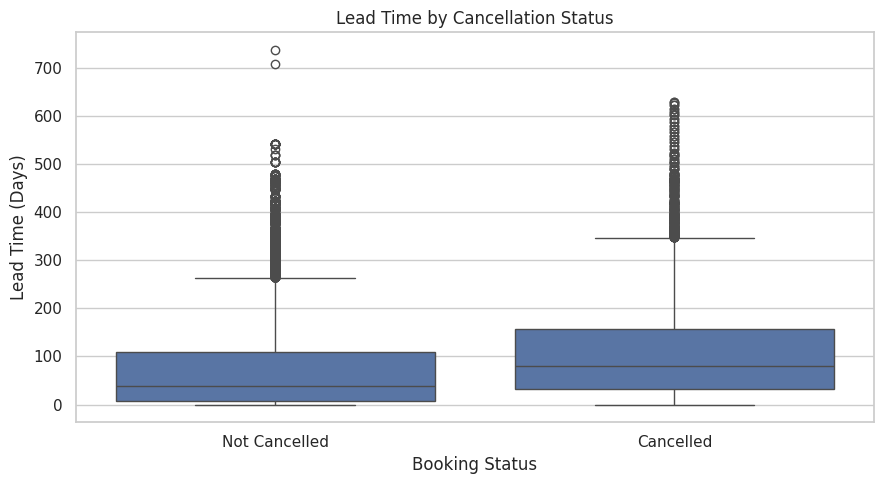

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    x=df['is_canceled'].map({
        0: 'Not Cancelled',
        1: 'Cancelled'
    }),
    y=df['lead_time']
)

plt.title('Lead Time by Cancellation Status')
plt.xlabel('Booking Status')
plt.ylabel('Lead Time (Days)')

plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import mannwhitneyu

u_statistic, p_value = mannwhitneyu(
    not_cancelled,
    cancelled,
    alternative='two-sided'
)

print("Mann-Whitney U Statistic:", u_statistic)
print("p-value:", p_value)

Mann-Whitney U Statistic: 538471866.0
p-value: 0.0


## 7.3 ADR — Mann–Whitney U Test


In [ ]:
not_cancelled_adr = df[df['is_canceled'] == 0]['adr']
cancelled_adr = df[df['is_canceled'] == 1]['adr']

print("Not Cancelled ADR")
print(not_cancelled_adr.describe())

print("\nCancelled ADR")
print(cancelled_adr.describe())

Not Cancelled ADR
count    63371.000000
mean       102.001961
std         51.393422
min         -6.380000
25%         67.990000
50%         94.500000
75%        129.200000
max        510.000000
Name: adr, dtype: float64

Cancelled ADR
count    24025.000000
mean       117.772476
std         62.149188
min          0.000000
25%         81.000000
50%        109.800000
75%        144.000000
max       5400.000000
Name: adr, dtype: float64


In [ ]:
from scipy.stats import mannwhitneyu

u_statistic, p_value = mannwhitneyu(
    not_cancelled_adr,
    cancelled_adr,
    alternative='two-sided'
)

print("Mann-Whitney U Statistic:", u_statistic)
print("p-value:", p_value)

Mann-Whitney U Statistic: 620667349.5
p-value: 0.0


A Mann–Whitney U test found a statistically significant difference in ADR between cancelled and non-cancelled bookings (U = 620,667,349.5, p < 0.001). Cancelled bookings had a higher median ADR (109.80) than non-cancelled bookings (94.50), suggesting that higher-priced bookings are associated with cancellation behavior. However, this statistical association does not imply that higher ADR causes cancellations.

## 7.4 Total Stay Duration — Mann–Whitney U Test


In [ ]:
not_cancelled_stay = df[df['is_canceled'] == 0]['total_stay_nights']
cancelled_stay = df[df['is_canceled'] == 1]['total_stay_nights']

print("Not Cancelled Stay")
print(not_cancelled_stay.describe())

print("\nCancelled Stay")
print(cancelled_stay.describe())

Not Cancelled Stay
count    63371.000000
mean         3.487557
std          2.691306
min          0.000000
25%          2.000000
50%          3.000000
75%          4.000000
max         69.000000
Name: total_stay_nights, dtype: float64

Cancelled Stay
count    24025.000000
mean         4.008117
std          2.911786
min          0.000000
25%          2.000000
50%          3.000000
75%          5.000000
max         56.000000
Name: total_stay_nights, dtype: float64


In [ ]:
from scipy.stats import mannwhitneyu

u_statistic, p_value = mannwhitneyu(
    not_cancelled_stay,
    cancelled_stay,
    alternative='two-sided'
)

print("Mann-Whitney U Statistic:", u_statistic)
print("p-value:", p_value)

Mann-Whitney U Statistic: 660103231.5
p-value: 3.6125357937896847e-208


A Mann–Whitney U test found a statistically significant difference in total stay duration between cancelled and non-cancelled bookings (U = 660,103,231.5, p < 0.001). Cancelled bookings had a slightly higher average stay duration (4.01 nights) than non-cancelled bookings (3.49 nights). This indicates that stay duration is statistically associated with cancellation behavior, although the difference in average duration is relatively small.

## 7.5 Repeated Guest — Chi-Square Test


In [ ]:
contingency_table = pd.crosstab(
    df['is_repeated_guest'],
    df['is_canceled']
)

contingency_table

is_canceled,0,1
is_repeated_guest,,
0,60217,23764
1,3154,261


In [ ]:
from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-Square Statistic:", chi2)
print("p-value:", p_value)
print("Degrees of Freedom:", dof)

Chi-Square Statistic: 701.2645972208041
p-value: 1.587484637713458e-154
Degrees of Freedom: 1


In [ ]:
import numpy as np

n = contingency_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (
        n * min(
            contingency_table.shape[0] - 1,
            contingency_table.shape[1] - 1
        )
    )
)

print("Cramér's V:", cramers_v)

Cramér's V: 0.08957672479208614


A Chi-Square Test of Independence found a statistically significant association between repeated-guest status and cancellation status, χ²(1) = 701.26, p < 0.001. However, Cramér's V = 0.090 indicates that the strength of the association is weak. Although repeated guests showed substantially lower cancellation rates in the descriptive analysis (7.6% vs. 28.3%), repeated-guest status alone should not be considered a strong standalone predictor of cancellation.

## 7.6 Deposit Type — Chi-Square Test


In [ ]:
contingency_table = pd.crosstab(
    df['deposit_type'],
    df['is_canceled']
)

contingency_table

is_canceled,0,1
deposit_type,,
No Deposit,63235,23016
Non Refund,55,983
Refundable,81,26


In [ ]:
from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-Square Statistic:", chi2)
print("p-value:", p_value)
print("Degrees of Freedom:", dof)

Chi-Square Statistic: 2380.9964658431845
p-value: 0.0
Degrees of Freedom: 2


In [ ]:
import numpy as np

n = contingency_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (
        n * min(
            contingency_table.shape[0] - 1,
            contingency_table.shape[1] - 1
        )
    )
)

print("Cramér's V:", cramers_v)

Cramér's V: 0.1650568670092744


A Chi-Square Test of Independence found a statistically significant association between deposit type and cancellation status, χ²(2) = 2381.00, p < 0.001. Cramér's V = 0.165 indicates a relatively weak association. Descriptively, non-refundable bookings had a substantially higher cancellation rate (94.7%) than bookings with no deposit (26.7%) or refundable bookings (24.3%). Therefore, deposit type is an important variable to consider when assessing cancellation risk, although it should not be interpreted as a causal factor.

## 7.7 Statistical Summary and Effect Sizes


In [ ]:
statistical_summary = pd.DataFrame({
    'Variable': [
        'Customer Type',
        'Lead Time',
        'ADR',
        'Total Stay Duration',
        'Repeated Guest',
        'Deposit Type'
    ],

    'Test': [
        'Chi-Square',
        'Mann-Whitney U',
        'Mann-Whitney U',
        'Mann-Whitney U',
        'Chi-Square',
        'Chi-Square'
    ],

    'Test Statistic': [
        1411.2015,
        538471866.0,
        620667349.5,
        660103231.5,
        701.2646,
        2380.9965
    ],

    'p-value': [
        1.0928e-305,
        0.0,
        0.0,
        3.6125e-208,
        1.5875e-154,
        0.0
    ],

    'Effect Size': [
        0.1271,
        np.nan,
        np.nan,
        np.nan,
        0.0896,
        0.1651
    ],

    'Effect Size Measure': [
        "Cramér's V",
        "Not calculated",
        "Not calculated",
        "Not calculated",
        "Cramér's V",
        "Cramér's V"
    ]
})

statistical_summary

,Variable,Test,Test Statistic,p-value,Effect Size,Effect Size Measure
0,Customer Type,Chi-Square,1.411201e+03,1.092800e-305,0.1271,Cramér's V
1,Lead Time,Mann-Whitney U,5.384719e+08,0.000000e+00,NaN,Not calculated
2,ADR,Mann-Whitney U,6.206673e+08,0.000000e+00,NaN,Not calculated
3,Total Stay Duration,Mann-Whitney U,6.601032e+08,3.612500e-208,NaN,Not calculated
4,Repeated Guest,Chi-Square,7.012646e+02,1.587500e-154,0.0896,Cramér's V
5,Deposit Type,Chi-Square,2.380997e+03,0.000000e+00,0.1651,Cramér's V


In [ ]:
def rank_biserial_correlation(x, y, u_statistic):
    n1 = len(x)
    n2 = len(y)

    return 1 - (2 * u_statistic) / (n1 * n2)


lead_time_effect = rank_biserial_correlation(
    not_cancelled,
    cancelled,
    538471866.0
)

adr_effect = rank_biserial_correlation(
    not_cancelled_adr,
    cancelled_adr,
    620667349.5
)

stay_effect = rank_biserial_correlation(
    not_cancelled_stay,
    cancelled_stay,
    660103231.5
)

print("Lead Time Effect Size:", lead_time_effect)
print("ADR Effect Size:", adr_effect)
print("Total Stay Duration Effect Size:", stay_effect)

Lead Time Effect Size: 0.29264234760691343
ADR Effect Size: 0.18466715351223317
Total Stay Duration Effect Size: 0.1328626402722215


In [ ]:
statistical_summary = pd.DataFrame({
    'Variable': [
        'Customer Type',
        'Lead Time',
        'ADR',
        'Total Stay Duration',
        'Repeated Guest',
        'Deposit Type'
    ],

    'Test': [
        'Chi-Square',
        'Mann-Whitney U',
        'Mann-Whitney U',
        'Mann-Whitney U',
        'Chi-Square',
        'Chi-Square'
    ],

    'Test Statistic': [
        1411.2015,
        538471866.0,
        620667349.5,
        660103231.5,
        701.2646,
        2380.9965
    ],

    'p-value': [
        1.0928e-305,
        0.0,
        0.0,
        3.6125e-208,
        1.5875e-154,
        0.0
    ],

    'Effect Size': [
        0.1271,
        0.2926,
        0.1847,
        0.1329,
        0.0896,
        0.1651
    ],

    'Effect Size Measure': [
        "Cramér's V",
        "Rank-biserial correlation",
        "Rank-biserial correlation",
        "Rank-biserial correlation",
        "Cramér's V",
        "Cramér's V"
    ]
})

statistical_summary

,Variable,Test,Test Statistic,p-value,Effect Size,Effect Size Measure
0,Customer Type,Chi-Square,1.411201e+03,1.092800e-305,0.1271,Cramér's V
1,Lead Time,Mann-Whitney U,5.384719e+08,0.000000e+00,0.2926,Rank-biserial correlation
2,ADR,Mann-Whitney U,6.206673e+08,0.000000e+00,0.1847,Rank-biserial correlation
3,Total Stay Duration,Mann-Whitney U,6.601032e+08,3.612500e-208,0.1329,Rank-biserial correlation
4,Repeated Guest,Chi-Square,7.012646e+02,1.587500e-154,0.0896,Cramér's V
5,Deposit Type,Chi-Square,2.380997e+03,0.000000e+00,0.1651,Cramér's V


## 8. Interactive Business Dashboard


In [ ]:
# ==========================================
# INTERACTIVE BUSINESS INSIGHTS DASHBOARD
# ==========================================

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [ ]:
# Overall cancellation rate
overall_cancellation = df['is_canceled'].mean() * 100

# Hotel cancellation rates
hotel_cancellation = (
    df.groupby('hotel')['is_canceled'].mean() * 100
)

# Repeat guest cancellation rate
repeat_guest_cancellation = (
    df.groupby('is_repeated_guest')['is_canceled'].mean() * 100
)

# Deposit type cancellation rate
deposit_cancellation = (
    df.groupby('deposit_type')['is_canceled'].mean() * 100
)

print("Overall cancellation rate:", round(overall_cancellation, 1))
print("\nHotel cancellation:")
print(hotel_cancellation.round(1))

print("\nRepeat guest cancellation:")
print(repeat_guest_cancellation.round(1))

print("\nDeposit type cancellation:")
print(deposit_cancellation.round(1))

Overall cancellation rate: 27.5

Hotel cancellation:
hotel
City Hotel      30.0
Resort Hotel    23.5
Name: is_canceled, dtype: float64

Repeat guest cancellation:
is_repeated_guest
0    28.3
1     7.6
Name: is_canceled, dtype: float64

Deposit type cancellation:
deposit_type
No Deposit    26.7
Non Refund    94.7
Refundable    24.3
Name: is_canceled, dtype: float64


In [ ]:
lead_time_cancellation = (
    df.groupby('lead_time_group', observed=True)['is_canceled']
    .mean()
    .reset_index()
)

lead_time_cancellation['cancellation_rate'] = (
    lead_time_cancellation['is_canceled'] * 100
)

fig_lead = px.line(
    lead_time_cancellation,
    x='lead_time_group',
    y='cancellation_rate',
    markers=True,
    text='cancellation_rate',
    title='Cancellation Rate by Lead Time'
)

fig_lead.update_traces(
    texttemplate='%{text:.1f}%',
    textposition='top center'
)

fig_lead.update_layout(
    xaxis_title='Lead Time Before Arrival',
    yaxis_title='Cancellation Rate (%)',
    yaxis=dict(range=[0, 50]),
    height=450
)

fig_lead.show()

In [ ]:
hotel_plot = (
    df.groupby('hotel')['is_canceled']
    .mean()
    .reset_index()
)

hotel_plot['cancellation_rate'] = (
    hotel_plot['is_canceled'] * 100
)

fig_hotel = px.bar(
    hotel_plot,
    x='hotel',
    y='cancellation_rate',
    text='cancellation_rate',
    title='Cancellation Rate by Hotel Type'
)

fig_hotel.update_traces(
    texttemplate='%{text:.1f}%',
    textposition='outside'
)

fig_hotel.update_layout(
    xaxis_title='Hotel Type',
    yaxis_title='Cancellation Rate (%)',
    yaxis=dict(range=[0, 35]),
    height=400
)

fig_hotel.show()

In [ ]:
market_plot = (
    df.groupby('market_segment')['is_canceled']
    .mean()
    .reset_index()
)

market_plot['cancellation_rate'] = (
    market_plot['is_canceled'] * 100
)

market_plot = market_plot.sort_values(
    'cancellation_rate',
    ascending=True
)

fig_market = px.bar(
    market_plot,
    x='cancellation_rate',
    y='market_segment',
    orientation='h',
    text='cancellation_rate',
    title='Cancellation Rate by Market Segment'
)

fig_market.update_traces(
    texttemplate='%{text:.1f}%',
    textposition='outside'
)

fig_market.update_layout(
    xaxis_title='Cancellation Rate (%)',
    yaxis_title='Market Segment',
    height=450
)

fig_market.show()

In [ ]:
fig = make_subplots(
    rows=2,
    cols=4,
    specs=[
        [
            {"type": "indicator"},
            {"type": "indicator"},
            {"type": "indicator"},
            {"type": "indicator"}
        ],
        [
            {"type": "xy", "colspan": 4},
            None,
            None,
            None
        ]
    ],
    row_heights=[0.25, 0.75],
    vertical_spacing=0.12
)

# -----------------------------------
# KPI 1: Overall cancellation
# -----------------------------------

fig.add_trace(
    go.Indicator(
        mode="number",
        value=overall_cancellation,
        number={"suffix": "%", "valueformat": ".1f"},
        title={"text": "Overall Cancellation"}
    ),
    row=1,
    col=1
)

# -----------------------------------
# KPI 2: City Hotel
# -----------------------------------

city_rate = hotel_cancellation['City Hotel']

fig.add_trace(
    go.Indicator(
        mode="number",
        value=city_rate,
        number={"suffix": "%", "valueformat": ".1f"},
        title={"text": "City Hotel"}
    ),
    row=1,
    col=2
)

# -----------------------------------
# KPI 3: Repeat Guest
# -----------------------------------

repeat_rate = repeat_guest_cancellation[1]

fig.add_trace(
    go.Indicator(
        mode="number",
        value=repeat_rate,
        number={"suffix": "%", "valueformat": ".1f"},
        title={"text": "Repeat Guest"}
    ),
    row=1,
    col=3
)

# -----------------------------------
# KPI 4: Non Refund
# -----------------------------------

non_refund_rate = deposit_cancellation['Non Refund']

fig.add_trace(
    go.Indicator(
        mode="number",
        value=non_refund_rate,
        number={"suffix": "%", "valueformat": ".1f"},
        title={"text": "Non-Refundable"}
    ),
    row=1,
    col=4
)

# -----------------------------------
# Lead Time Chart
# -----------------------------------

fig.add_trace(
    go.Scatter(
        x=lead_time_cancellation['lead_time_group'].astype(str),
        y=lead_time_cancellation['cancellation_rate'],
        mode='lines+markers+text',
        text=[
            f"{x:.1f}%"
            for x in lead_time_cancellation['cancellation_rate']
        ],
        textposition='top center',
        name='Cancellation Rate'
    ),
    row=2,
    col=1
)

fig.update_layout(
    title={
        'text': '🏨 Hotel Booking & Cancellation Analysis',
        'x': 0.5
    },
    height=800,
    showlegend=False
)

fig.update_xaxes(
    title_text='Lead Time Before Arrival',
    row=2,
    col=1
)

fig.update_yaxes(
    title_text='Cancellation Rate (%)',
    range=[0, 50],
    row=2,
    col=1
)

fig.show()

In [ ]:
# Customer Type Cancellation Rate

customer_plot = (
    df.groupby('customer_type')['is_canceled']
    .mean()
    .reset_index()
)

customer_plot['cancellation_rate'] = (
    customer_plot['is_canceled'] * 100
)

customer_plot = customer_plot.sort_values(
    'cancellation_rate',
    ascending=True
)

fig_customer = px.bar(
    customer_plot,
    x='cancellation_rate',
    y='customer_type',
    orientation='h',
    text='cancellation_rate',
    title='Cancellation Rate by Customer Type'
)

fig_customer.update_traces(
    texttemplate='%{text:.1f}%',
    textposition='outside'
)

fig_customer.update_layout(
    xaxis_title='Cancellation Rate (%)',
    yaxis_title='Customer Type',
    height=450
)

fig_customer.show()

## 9. Statistical Evidence


## Statistical Evidence

Statistical hypothesis testing was used to determine whether selected booking characteristics were significantly associated with cancellation status.

Both Chi-Square tests and Mann-Whitney U tests were used depending on the type of variable. Effect sizes were also calculated to understand the practical strength of the observed relationships.

In [ ]:
# ==========================================
# STATISTICAL EVIDENCE SUMMARY
# ==========================================

statistical_summary = pd.DataFrame({
    'Variable': [
        'Customer Type',
        'Lead Time',
        'ADR',
        'Total Stay Duration',
        'Repeated Guest',
        'Deposit Type'
    ],

    'Test': [
        'Chi-Square',
        'Mann-Whitney U',
        'Mann-Whitney U',
        'Mann-Whitney U',
        'Chi-Square',
        'Chi-Square'
    ],

    'Test Statistic': [
        1411.2015,
        538471866.0,
        620667349.5,
        660103231.5,
        701.2646,
        2380.9965
    ],

    'p-value': [
        1.0928e-305,
        0.0,
        0.0,
        3.6125e-208,
        1.5875e-154,
        0.0
    ],

    'Effect Size': [
        0.1271,
        0.2926,
        0.1847,
        0.1329,
        0.0896,
        0.1651
    ],

    'Effect Size Measure': [
        "Cramér's V",
        'Rank-biserial correlation',
        'Rank-biserial correlation',
        'Rank-biserial correlation',
        "Cramér's V",
        "Cramér's V"
    ]
})

statistical_summary

,Variable,Test,Test Statistic,p-value,Effect Size,Effect Size Measure
0,Customer Type,Chi-Square,1.411201e+03,1.092800e-305,0.1271,Cramér's V
1,Lead Time,Mann-Whitney U,5.384719e+08,0.000000e+00,0.2926,Rank-biserial correlation
2,ADR,Mann-Whitney U,6.206673e+08,0.000000e+00,0.1847,Rank-biserial correlation
3,Total Stay Duration,Mann-Whitney U,6.601032e+08,3.612500e-208,0.1329,Rank-biserial correlation
4,Repeated Guest,Chi-Square,7.012646e+02,1.587500e-154,0.0896,Cramér's V
5,Deposit Type,Chi-Square,2.380997e+03,0.000000e+00,0.1651,Cramér's V


## 10. Key Business Insights

### 1. Lead Time
Cancellation rates increased from **18.6%** for bookings made 0–30 days before arrival to **40.9%** for bookings made more than 365 days in advance.

### 2. Hotel Type
City Hotel had a higher cancellation rate (**30.0%**) than Resort Hotel (**23.5%**).

### 3. Market Segment
Online TA bookings showed a relatively high cancellation rate of approximately **35.3%**.

### 4. Returning Customers
Repeated guests had a substantially lower cancellation rate (**7.6%**) than non-repeated guests (**28.3%**).

### 5. Deposit Type
Non-refundable bookings showed an exceptionally high cancellation rate (**94.7%**). This should be interpreted as an association, not proof of causation.

### 6. Customer Type
Transient bookings had the highest cancellation rate among customer types (**30.1%**), while Group bookings had the lowest (**9.9%**).

### 7. Statistical Evidence
Among the tested variables, **lead time showed the largest effect size** (rank-biserial correlation = **0.293**). The remaining tested relationships had more modest effect sizes.



## 11. Business Recommendations


## Business Recommendations

Based on the exploratory analysis and statistical testing, the following recommendations can help hotels improve cancellation management:

### 1. Monitor long-lead-time bookings
Bookings made far in advance showed higher cancellation rates. Hotels should prioritize long-lead-time reservations for confirmation reminders and proactive cancellation-risk monitoring.

### 2. Pay closer attention to Online TA bookings
Online Travel Agent bookings had a relatively high cancellation rate of approximately 35.3%. Hotels could use targeted confirmation messages and flexible but controlled booking policies for this segment.

### 3. Develop hotel-specific cancellation strategies
City Hotel showed a higher overall cancellation rate than Resort Hotel. Therefore, cancellation-management strategies should be tailored to the characteristics of each hotel rather than applying one policy to both.

### 4. Identify and retain reliable returning customers
Repeated guests had a substantially lower cancellation rate than non-repeated guests. Hotels can strengthen loyalty programs and personalized offers for returning customers.

### 5. Monitor high-risk booking characteristics
Non-refundable bookings, longer planned stays, and certain customer segments showed notable associations with cancellation. These characteristics can be incorporated into a broader cancellation-risk monitoring framework.

### 6. Use statistical evidence when making decisions
The analysis showed statistically significant relationships between several booking characteristics and cancellation status. However, effect sizes were generally modest. Therefore, hotels should avoid relying on any single variable and instead consider multiple booking characteristics together.

## 12. Conclusion


## Conclusion

This project analyzed hotel booking data to identify factors associated with booking cancellations and to derive actionable business insights.

The analysis showed that cancellation behavior varies across several booking characteristics. Longer lead times were associated with higher cancellation rates, with bookings made more than 365 days in advance showing a cancellation rate of approximately 40.9%, compared with 18.6% for bookings made within 30 days. City Hotel also showed a higher overall cancellation rate than Resort Hotel.

Customer and booking characteristics were also important. Online Travel Agent bookings showed a relatively high cancellation rate, while repeated guests had substantially lower cancellation rates than non-repeated guests. Longer planned stays and certain customer types were also associated with higher cancellation rates.

Statistical hypothesis testing supported these findings. All six tested variables showed statistically significant associations with cancellation status. However, the effect sizes were generally modest, with lead time showing the largest effect among the variables tested.

Overall, the findings suggest that hotels can improve cancellation management by identifying higher-risk bookings early, monitoring long-lead-time and Online TA reservations, developing hotel-specific strategies, and using customer history to support more targeted decision-making.

This project demonstrates how exploratory data analysis, statistical testing, data visualization, and business reasoning can be combined to transform raw hotel booking data into actionable insights.